Logistic Regression Model: Risk_Level ~ AVG_NOISE_LVL
Data Split: 80% Train (3099 rows) | 20% Test (775 rows)
Test Accuracy Score: 100.00%
Prediction: When AVG_NOISE_LVL =   1  -->  Predicted Class: 1 (Confidence: 100.00%)
Prediction: When AVG_NOISE_LVL = 100  -->  Predicted Class: 3 (Confidence: 100.00%)


C:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


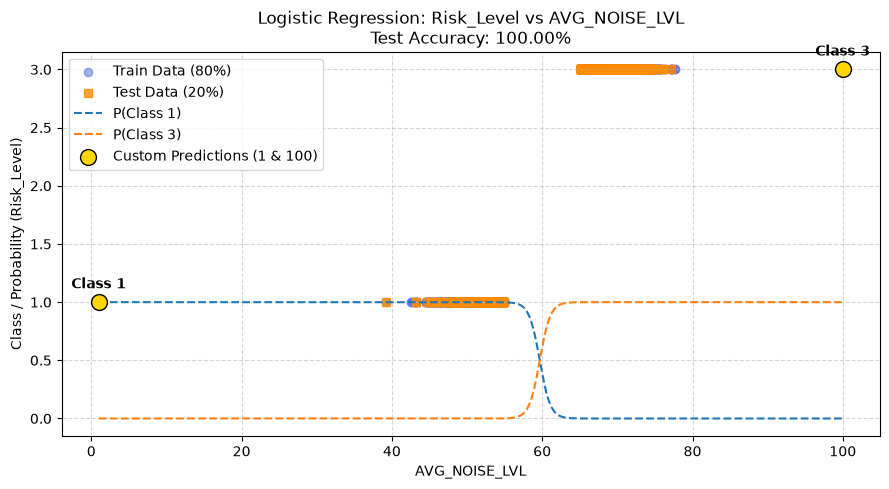

Logistic Regression Model: Risk_Level ~ Duration_hours
Data Split: 80% Train (3099 rows) | 20% Test (775 rows)
Test Accuracy Score: 75.10%
Prediction: When Duration_hours =   1  -->  Predicted Class: 3 (Confidence: 61.76%)
Prediction: When Duration_hours = 100  -->  Predicted Class: 3 (Confidence: 99.91%)


C:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


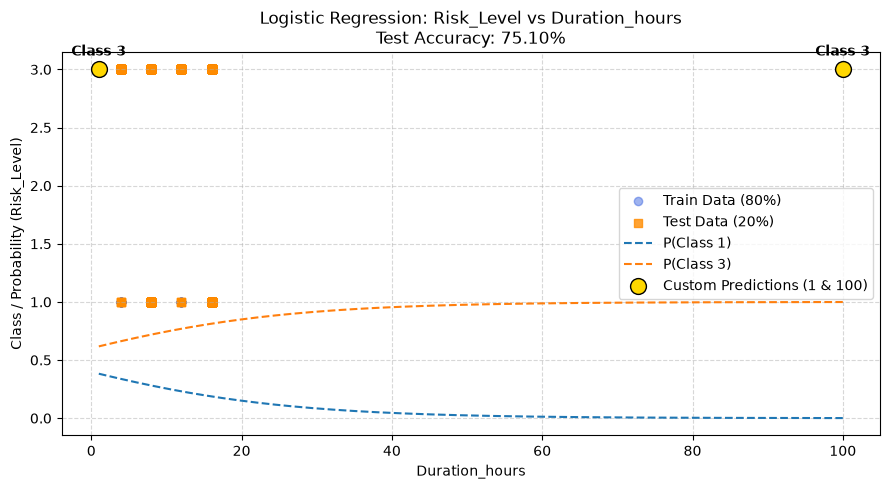

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

# ==========================================================
# Load Excel File
# ==========================================================
file_path = r"Road_noise_measurements_filled (1).xlsx"
df = pd.read_excel(file_path, sheet_name="Road_noise_measurements")

# ==========================================================
# Convert Categorical Risk Level to Discrete Classes
# ==========================================================
df["Risk_Level"] = df["Risk_Level"].astype(str).str.strip().str.lower()
risk_mapping = {"low": 1, "medium": 2, "high": 3}
df["Risk_Level"] = df["Risk_Level"].map(risk_mapping)

# ==========================================================
# Logistic Regression, 80/20 Split & Prediction Function
# ==========================================================
def logistic_regression_model(df, x_col, y_col, custom_inputs=[1, 100], test_size=0.20, random_state=42):
    # Prepare and clean data
    data = df[[x_col, y_col]].copy()
    data[x_col] = pd.to_numeric(data[x_col], errors="coerce")
    data[y_col] = pd.to_numeric(data[y_col], errors="coerce")
    data = data.dropna()

    # Logistic regression requires discrete integer class targets
    data[y_col] = data[y_col].astype(int)

    if len(data) < 5 or data[y_col].nunique() < 2:
        print(f"Skipping {y_col} ~ {x_col}: Needs at least 2 distinct target classes.")
        return

    # Split dataset: 80% Train, 20% Test
    X = data[[x_col]]
    y = data[y_col]
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=test_size, random_state=random_state, stratify=y if y.value_counts().min() >= 2 else None
    )

    # 1. Train Logistic Regression Model (Multi-class compatible via multinomial/ovr)
    clf = LogisticRegression(max_iter=1000)
    clf.fit(X_train, y_train)

    # 2. Predict on 20% Test Data to compute classification accuracy percentage
    y_test_pred = clf.predict(X_test)
    test_accuracy = accuracy_score(y_test, y_test_pred) * 100

    # 3. Predict Classes & Probabilities for Custom Inputs (X = 1 and X = 100)
    custom_df = pd.DataFrame({x_col: custom_inputs})
    custom_preds = clf.predict(custom_df)
    custom_probs = clf.predict_proba(custom_df)

    print("=" * 65)
    print(f"Logistic Regression Model: {y_col} ~ {x_col}")
    print(f"Data Split: {int((1-test_size)*100)}% Train ({len(X_train)} rows) | {int(test_size*100)}% Test ({len(X_test)} rows)")
    print(f"Test Accuracy Score: {test_accuracy:.2f}%")
    for val, pred_class, probs in zip(custom_inputs, custom_preds, custom_probs):
        max_p = np.max(probs) * 100
        print(f"Prediction: When {x_col} = {val:>3}  -->  Predicted Class: {pred_class} (Confidence: {max_p:.2f}%)")
    print("=" * 65)

    # ======================================================
    # Single Visual Plot (Probability Curves & Class Boundaries)
    # ======================================================
    plt.figure(figsize=(9, 5))

    # Actual Data Points
    plt.scatter(
        X_train[x_col], y_train,
        color="royalblue", alpha=0.5, label=f"Train Data ({int((1-test_size)*100)}%)"
    )
    plt.scatter(
        X_test[x_col], y_test,
        color="darkorange", alpha=0.8, marker="s", label=f"Test Data ({int(test_size*100)}%)"
    )

    # Logistic Probability Curves across feature range
    min_x = min(data[x_col].min(), min(custom_inputs))
    max_x = max(data[x_col].max(), max(custom_inputs))
    x_range = np.linspace(min_x, max_x, 300).reshape(-1, 1)
    probabilities = clf.predict_proba(x_range)

    for idx, class_label in enumerate(clf.classes_):
        plt.plot(
            x_range,
            probabilities[:, idx],
            linestyle="--",
            label=f"P(Class {class_label})"
        )

    # Highlight Custom Prediction Points
    plt.scatter(
        custom_inputs, custom_preds,
        color="gold", edgecolors="black", s=130, zorder=5, label="Custom Predictions (1 & 100)"
    )

    for val, pred_class in zip(custom_inputs, custom_preds):
        plt.annotate(
            f"Class {pred_class}",
            (val, pred_class),
            textcoords="offset points",
            xytext=(0, 10),
            ha="center",
            fontweight="bold"
        )

    plt.xlabel(x_col)
    plt.ylabel(f"Class / Probability ({y_col})")
    plt.title(f"Logistic Regression: {y_col} vs {x_col}\nTest Accuracy: {test_accuracy:.2f}%")
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.legend(loc="best")
    plt.tight_layout()

    plt.savefig(f"{y_col}_vs_{x_col}_Logistic.png", dpi=300)
    plt.show()

# ==========================================================
# Run Logistic Regression (Target must be a categorical label)
# ==========================================================
logistic_pairs = [
    ("AVG_NOISE_LVL", "Risk_Level"),
    ("Duration_hours", "Risk_Level"),
]

for x_var, y_var in logistic_pairs:
    logistic_regression_model(df, x_var, y_var, custom_inputs=[1, 100], test_size=0.20)